# Ex 1

True


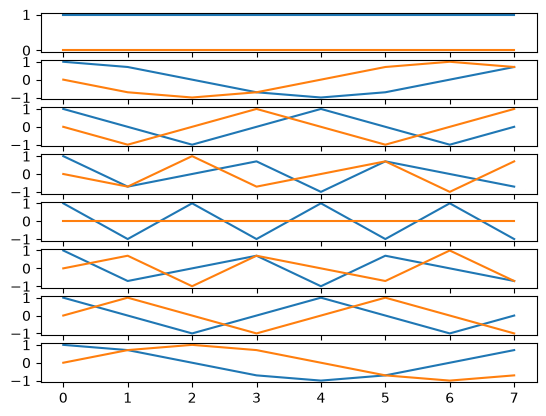

In [8]:
import numpy as np
import matplotlib.pyplot as plt

N = 8
n = np.arange(N)
F = np.exp(-2j * np.pi * np.outer(n, n) / N)

fig, axs = plt.subplots(N)
for i in range(N):
    axs[i].plot(F[i].real)
    axs[i].plot(F[i].imag)

print(np.allclose(F.conj().T @ F, N * np.eye(N)))

fig.savefig('ex1.pdf')

# Ex 2

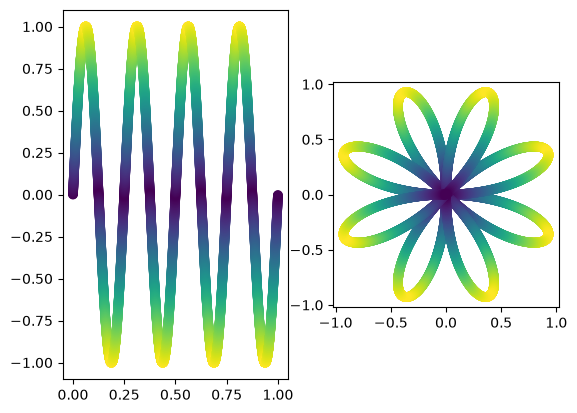

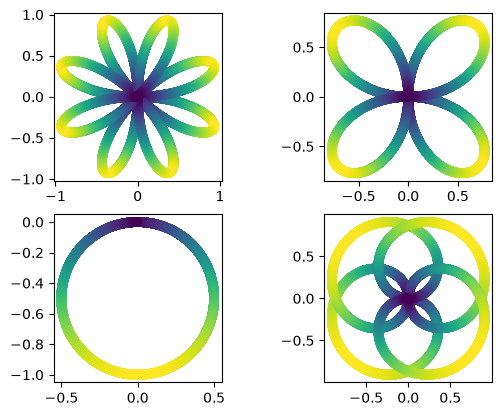

In [9]:
N = 10000
t = np.arange(N) / N
x = np.sin(2 * np.pi * 4 * t)

y = x * np.exp(-2j * np.pi * t)

fig, axs = plt.subplots(1, 2)
axs[0].scatter(t, x, c=np.abs(x))
axs[1].scatter(y.real, y.imag, c=np.abs(y))
axs[1].set_aspect('equal')

fig.savefig('ex2_1.pdf')

fig, axs = plt.subplots(2, 2)
ws = [1, 2, 4, 6]

for i in range(4):
    w = ws[i]

    z = x * np.exp(-2j * np.pi * w * t)
    axs.flat[i].scatter(z.real, z.imag, c=np.abs(z))
    axs.flat[i].set_aspect('equal')

fig.savefig('ex2_2.pdf')

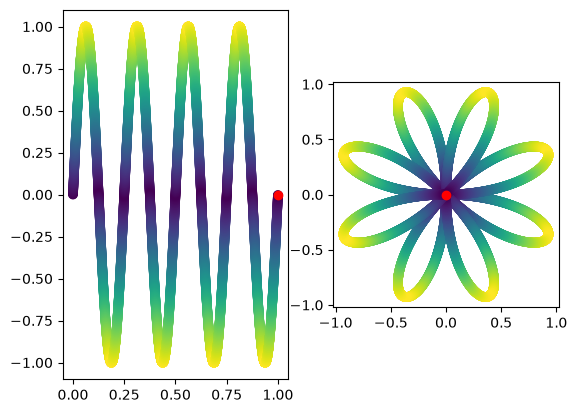

In [10]:
from IPython.display import clear_output

for k in range(250, N + 1, 250):
    y = x[:k] * np.exp(-2j * np.pi * t[:k])

    fig, axs = plt.subplots(1, 2)
    axs[0].scatter(t[:k], x[:k], c=np.abs(x[:k]), vmin=0, vmax=1)
    axs[1].scatter(y.real, y.imag, c=np.abs(y), vmin=0, vmax=1)
    axs[0].plot(t[k - 1], x[k - 1], 'ro')
    axs[1].plot(y.real[-1], y.imag[-1], 'ro')
    axs[1].set_aspect('equal')
    clear_output(wait=True)
    plt.show()

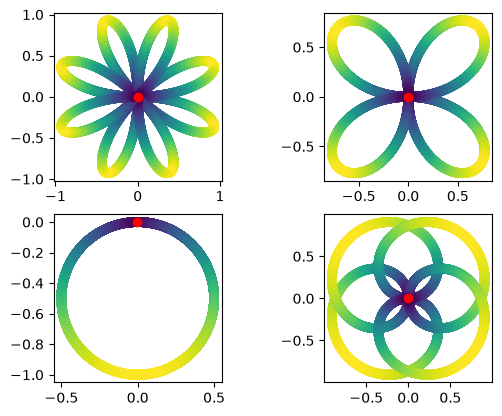

In [11]:
for k in range(250, N + 1, 250):
    fig, axs = plt.subplots(2, 2)
    for i in range(4):
        z = x[:k] * np.exp(-2j * np.pi * ws[i] * t[:k])
        axs.flat[i].scatter(z.real, z.imag, c=np.abs(z), vmin=0, vmax=1)
        axs.flat[i].plot(z.real[-1], z.imag[-1], 'ro')
        axs.flat[i].set_aspect('equal')
    clear_output(wait=True)
    plt.show()

# Ex 3

True


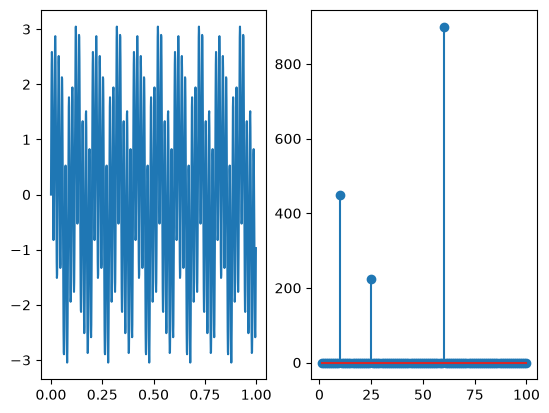

In [12]:
N = 900
t = np.arange(N) / N
x = np.sin(2 * np.pi * 10 * t) + 0.5 * np.sin(2 * np.pi * 25 * t) + 2 * np.sin(2 * np.pi * 60 * t)

ws = np.arange(1, 101)

X = np.zeros(len(ws), dtype=complex)
for i in range(len(ws)):
    for n in range(N):
        X[i] += x[n] * np.exp(-2j * np.pi * n * ws[i] / N)

F = np.exp(-2j * np.pi * np.outer(ws, np.arange(N)) / N)
print(np.allclose(X, F @ x))

fig, axs = plt.subplots(1, 2)
axs[0].plot(t, x)
axs[1].stem(ws, np.abs(X))
fig.savefig('ex3.pdf')